# WER Challenge

## Inhaltsverzeichnis

- [Vorwort](#vorwort)
- [Einleitung](#einleitung)
- [Definition der Fragestellung](#definition-der-fragestellung)
- [Hypothese](#hypothese)
- [Lösungsstrategie](#lösungsstrategie)
- [Einlesen von Dateien und kombinieren](#einlesen-von-dateien-und-kombinieren)
- [Systemdefinition](#systemdefinition)
- [Korrelations Plot](#korrelations-plot)
- [Analyse der Korrelationen](#analyse-der-korrelationen)
  - [Die Gesamtbewoelkung](#die-gesamtbewoelkung)
  - [Die Luftfeuchtigkeit](#die-luftfeuchtigkeit)
  - [Der Luftdruck](#der-luftdruck)
  - [Der Scope](#der-scope)
  - [Die Jahreszeiten - Faktor Zeit](#die-jahreszeiten---faktor-zeit)
- [Wahrscheinlichkeitsmodell](#wahrscheinlichkeitsmodell)
- [Abhängigkeiten und Unsicherheiten](#abhaengigkeiten-und-unsicherheiten)
- [Erweiterung durch neue Erkenntnisse](#erweiterung-durch-neue-erkenntnisse)

# Vorwort

Auf dieser Open Mini Challenge haben sich Michaela Brutenic, Roberto Fazekas und Emircan Bagcivan beteiligt.

# Einleitung
Die vorliegende Open Mini Challenge hat als Ziel die Entwicklung eines Wahrscheinlichkeitsmodells, das vorhersagt, ob es am nächsten Tag in Basel regnen wird. Grundlage für die Modellierung bilden regionale Wetterdaten aus den Jahren 2020 bis 2025, die eine Vielzahl meteorologischer Merkmale wie Temperatur, Luftfeuchtigkeit, Luftdruck, Windverhältnisse und Niederschlagsmengen enthalten.

Ziel ist es, auf Basis dieser Daten mithilfe klassischer Methoden der Wahrscheinlichkeitsrechnung – wie etwa bedingter Wahrscheinlichkeiten, Häufigkeitsverteilungen, Übergangswahrscheinlichkeiten oder auch einfacher stochastischer Modelle – ein mathematisches Modell zu konstruieren, dass die Regenwahrscheinlichkeit für den folge Tag beschreibt.

Die vollständige Datenlage erlaubt dabei eine fundierte Analyse, um die Abhängigkeiten zwischen Wettermerkmalen und Regenereignissen zu untersuchen. Das Modell soll dabei nicht nur eine Ja/Nein-Aussage treffen,  [sondern explizit die Wahrscheinlichkeit eines Regenereignisses angeben.]  Es bietet somit einen praktischen Anwendungsfall für stochastische Denkweisen im realweltlichen Kontext der Wettervorhersage.

Die Daten liegen in strukturierter Form vor und ermöglichen sowohl eine fundierte explorative Analyse als auch die Anwendung klassischer Verfahren der Wahrscheinlichkeitsrechnung. Ziel ist es, ein robustes, nachvollziehbares Modell zu entwickeln, das verlässliche Aussagen zur Regenwahrscheinlichkeit liefert 

# Definition der Fragestellung
Im Zentrum dieser Arbeit steht die folgende Fragestellung:

Wie lässt sich auf Grundlage historischer Wetterdaten die Wahrscheinlichkeit eines Regenereignisses für den folgenden Tag in Basel mathematisch modellieren?

Dabei sollen insbesondere stochastische Zusammenhänge zwischen verschiedenen meteorologischen Einflussgrößen und dem Auftreten von Regenereignissen identifiziert und in ein Wahrscheinlichkeitsmodell überführt werden. Das Ziel besteht darin, ein Modell zu entwickeln, das auf klar definierten, datenbasierten Regeln beruht und eine quantifizierte Vorhersage zur Regenwahrscheinlichkeit erlaubt – anstelle einer binären Entscheidung. Was unsere Fragestellung klar zu einer probabilistischen Fragestellung macht. Wir interessieren uns nicht für eine klare Ja / Nein Aussage, sondern für die Wahrscheinlichkeit - zu wie viel
Prozent es regnet.

# Hypothese
Es besteht ein signifikanter Zusammenhang zwischen bestimmten meteorologischen Variablen (z.B. Luftfeuchtigkeit, Bewölkung) und der Wahrscheinlichkeit des
Auftretens von Niederschlag. Ein geeignetes Wahrscheinlichkeitsmodell kann verwendet werden, um diesen Zusammenhang zu quantifizieren und zu prognostizieren.


# Lösungsstrategie

# Einlesen von Dateien und kombinieren

### Imports

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [22]:
df_2020 = pd.read_csv('data/wetterdaten_2020.csv', sep=';')
df_2021 = pd.read_csv('data/wetterdaten_2021.csv', sep=';')
df_2022 = pd.read_csv('data/wetterdaten_2022.csv', sep=';')
df_2023 = pd.read_csv('data/wetterdaten_2023.csv', sep=';')
df_2024 = pd.read_csv('data/wetterdaten_2024.csv', sep=';')
df_2025 = pd.read_csv('data/wetterdaten_2025.csv', sep=';')

print(df_2020.columns)


df_2020_2025_merged = pd.concat([
    df_2020,
    df_2021,
    df_2022,
    df_2023,
    df_2024,
    df_2025
], ignore_index=True)

# Umwandeln des Datums
df_2020_2025_merged['Datum'] = pd.to_datetime(df_2020_2025_merged['Datum'])

Index(['Datum', 'Jahr', 'Globalstrahlung in W/m2', 'Gesamtschneemenge',
       'Gesamtbewölkung', 'Luftdruck in hPa', 'Niederschlag',
       'Sonnenscheindauer', 'Tagesmittel Lufttemperatur',
       'Tagesminimum Lufttemperatur', 'Tagesmaximum Lufttemperatur',
       'Relative Luftfeuchtigkeit'],
      dtype='object')


# Systemdefinition
Damit wir unsere Hypothese beantworten können und wir nicht alle Informationen des Datensatzes brauchen, ist es nötig sich ein wenig einzuschränken.
Um fundiert zu wählen, auf welche Beobachtungen wir uns beschränken und wo wir die Grenze ziehen, ist der Ansatz die vorliegenden Daten zu analysieren sehr geeignet.
Dafür nutzen wir die Korrelation, welche Variabeln korrelieren mit dem Niederschlag am meisten? Dies gibt uns zwar noch keine klare einschätzung, ob ein
Einfluss festzustellen ist, jedoch immerhin eine Fährte.

## Korrelations Plot

Damit wir die Auswahl der Variablen fundiert treffen können untersuchen wir die Korrelationen der einzelnen
Beobachtungen. Unsere Wahl fällt dann auf die Beobachtung welche einerseits die höchste Korrelation zum
Niederschlag hat, sowie auf die Beobachtung welche aus meteorologischer Sicht Sinn macht.

In [11]:
# Zusammenfügen der Daten über die letzten fünf Jahre
df_2020_2025_merged_for_corr = df_2020_2025_merged[[
    'Globalstrahlung in W/m2',
    'Gesamtschneemenge',
    'Gesamtbewölkung',
    'Luftdruck in hPa',
    'Niederschlag',
    'Sonnenscheindauer',
    'Tagesmittel Lufttemperatur',
    'Tagesminimum Lufttemperatur',
    'Tagesmaximum Lufttemperatur',
    'Relative Luftfeuchtigkeit'
]]

# Korrelationen erkennen
df_correlation = df_2020_2025_merged_for_corr.corr()
df_correlation.style.background_gradient(cmap='coolwarm')

,Globalstrahlung in W/m2,Gesamtschneemenge,Gesamtbewölkung,Luftdruck in hPa,Niederschlag,Sonnenscheindauer,Tagesmittel Lufttemperatur,Tagesminimum Lufttemperatur,Tagesmaximum Lufttemperatur,Relative Luftfeuchtigkeit
Globalstrahlung in W/m2,1.000000,-0.123481,-0.612242,0.075762,-0.184369,0.876576,0.719938,0.550995,0.784065,-0.725688
Gesamtschneemenge,-0.123481,1.000000,0.069145,0.006758,-0.020547,-0.097889,-0.222621,-0.228159,-0.224008,0.078526
Gesamtbewölkung,-0.612242,0.069145,1.000000,-0.322901,0.306266,-0.831492,-0.247045,-0.061028,-0.357601,0.535739
Luftdruck in hPa,0.075762,0.006758,-0.322901,1.000000,-0.327941,0.224670,-0.135541,-0.191338,-0.088855,-0.035223
Niederschlag,-0.184369,-0.020547,0.306266,-0.327941,1.000000,-0.273878,0.064861,0.137679,0.034233,0.264342
Sonnenscheindauer,0.876576,-0.097889,-0.831492,0.224670,-0.273878,1.000000,0.507379,0.299324,0.610960,-0.702985
Tagesmittel Lufttemperatur,0.719938,-0.222621,-0.247045,-0.135541,0.064861,0.507379,1.000000,0.955118,0.978960,-0.444893
Tagesminimum Lufttemperatur,0.550995,-0.228159,-0.061028,-0.191338,0.137679,0.299324,0.955118,1.000000,0.890151,-0.242812
Tagesmaximum Lufttemperatur,0.784065,-0.224008,-0.357601,-0.088855,0.034233,0.610960,0.978960,0.890151,1.000000,-0.528576
Relative Luftfeuchtigkeit,-0.725688,0.078526,0.535739,-0.035223,0.264342,-0.702985,-0.444893,-0.242812,-0.528576,1.000000


## Analyse der Korrelationen
Damit wir nicht auf eine unübersichtliche Matrix schauen müssen ordnen wir die Werte der Korrelation der Grösse nach und
veranschaulichen die Werte in einem Barplot.

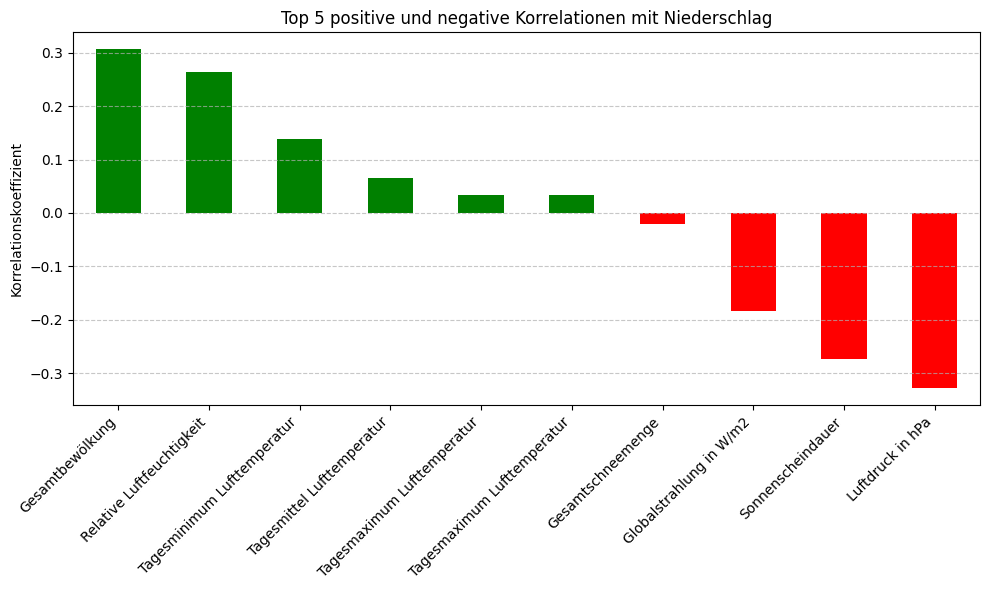

In [12]:
# Höchste wie tiefste Korrelationen
df_correlation_highest = (df_correlation["Niederschlag"].drop("Niederschlag")
                          .sort_values(ascending=False)).head(5)
df_correlation_lowes = (df_correlation["Niederschlag"]
                        .drop("Niederschlag").sort_values(ascending=True)).head(5)

combined_corr = (pd.concat([df_correlation_highest, df_correlation_lowes])
                 .sort_values(ascending=False))

plt.figure(figsize=(10, 6))
combined_corr.plot(kind='bar', color=['green' if corr > 0 else 'red' for corr in combined_corr.values])
plt.title("Top 5 positive und negative Korrelationen mit Niederschlag")
plt.ylabel("Korrelationskoeffizient")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Wenn wir den Plot ansehen dann fällt auf, dass die Gesamtbewölkung respektive der Luftdruck am stärksten positiv wie negativ korreliert.
Was ebenfalls im Vergleich zu den anderen Beobachtungen hohe wie tiefe Korrelationswerte hat, ist die Relative Luftfeuchtigkeit und die
Sonnenscheindauer. Die restlichen Werte sind nahe Nul, was nicht unbedingt auf einen nicht vorhandenen Zusammenhang hindeutet, jedoch
zu bedeuten hat, dass kein linearer Zusammenhang zu identifizieren ist.

### Zusammenhängende Variablen:

### Die Gesamtbewölung:


### Die Luftfeuchtigkeit:
Wenn die relative Luftfeuchtigkeit hoch ist, steigt die Wahrscheinlichkeit, dass der Sättigungspunkt
überschritten wird, sprich es Regnet. Wie viel Wasser die Luft aufnehmen kann hängt dabei von der
Temperatur ab.
(Stadler Form Luftfeuchtigkeit messen, 2023)„Luftfeuchtigkeitswerte beeinflussen Wetterberechnungen z.B. durch die Wasserdampfbilanzgleichung – diese Formel drückt den Einfluss der Luftfeuchtigkeit durch Regen und Kondensation aus und umgekehrt.“(Process Sensing Technologies, 2023)

### Der Luftdruck:


### Der Scope:


### Die Jahreszeiten - Faktor Zeit
Da es über die verschiedenen Jahreszeiten bzw. Monaten nicht gleich viel Regnet nehmen wir an, dass dies ebenfalls in unserem Modell berücksichtigt werden sollte, sollte sich ein Muster erkennen lassen. Falls dies nicht so wäre, so ist diese zeitliche Komponente nicht hilfreich für das Bestimmen der Regenwahrscheinlichkeit.

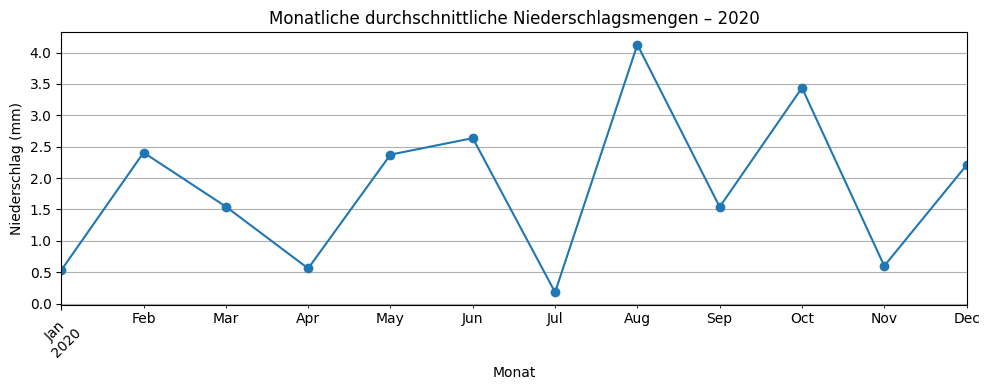

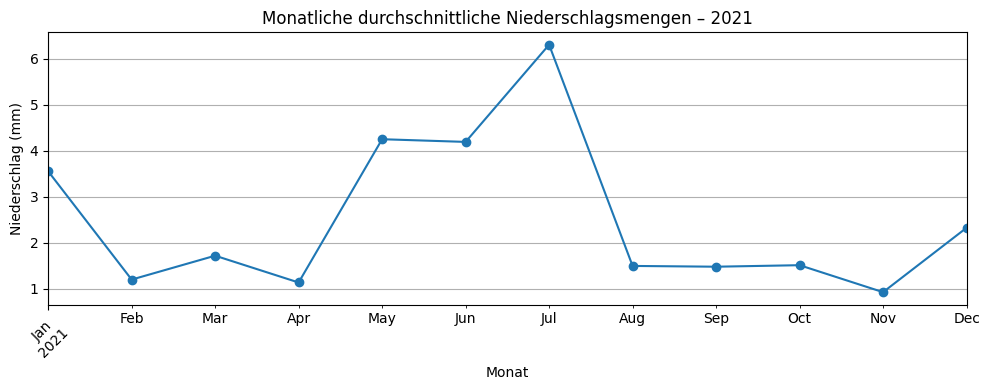

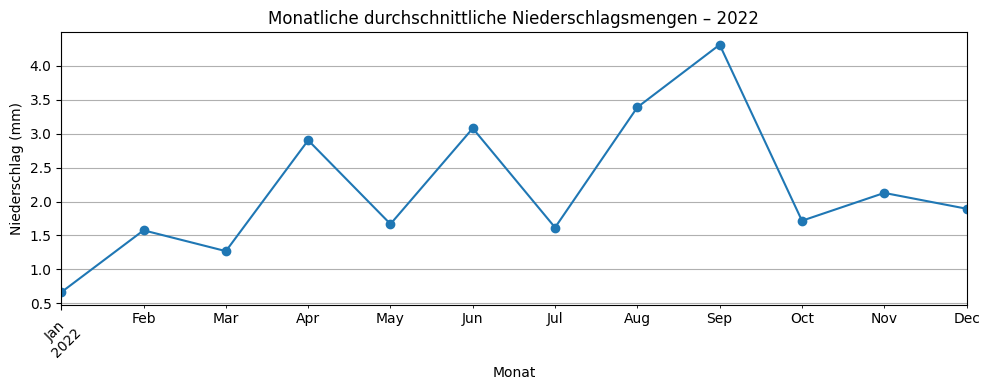

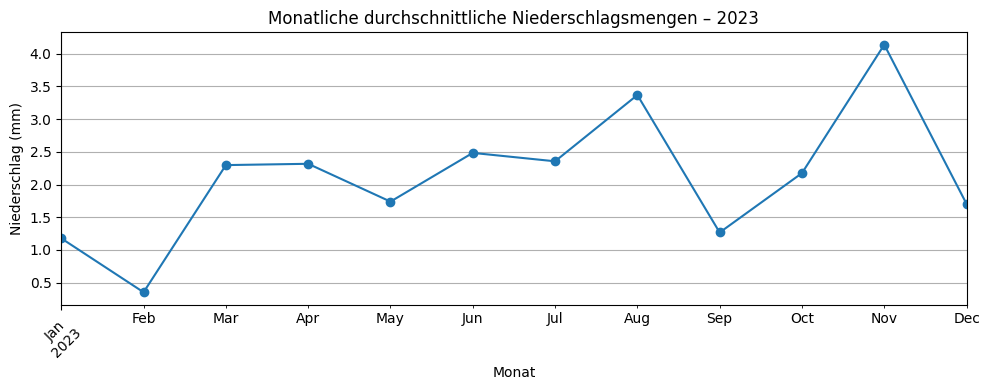

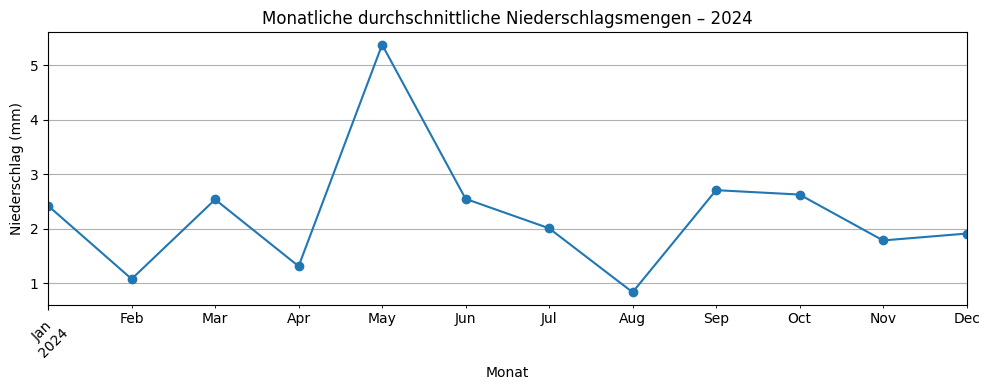

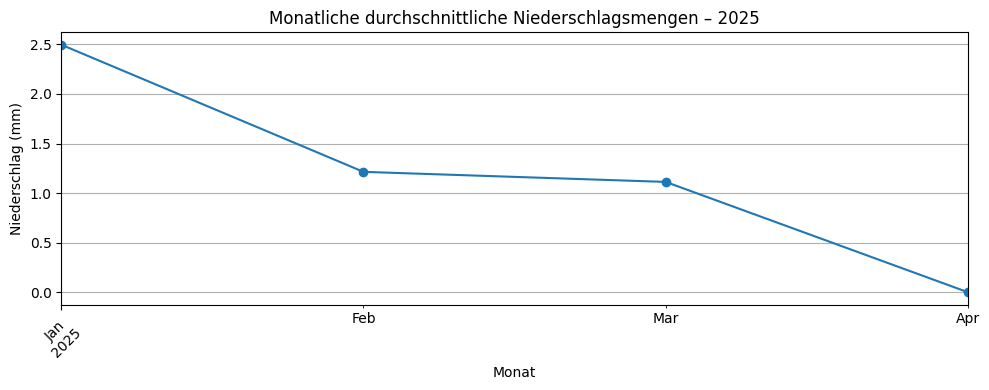

In [28]:
df_time_niederschlag = df_2020_2025_merged[['Datum', 'Niederschlag']]

df_time_niederschlag.set_index('Datum', inplace=True)

# Jahresliste (optional automatisch aus den Daten extrahieren)
jahre = df_time_niederschlag.index.year.unique()

# Plot pro Jahr
for jahr in sorted(jahre):
    # Daten für das Jahr filtern und monatlich mitteln
    monthly_avg = df_time_niederschlag[df_time_niederschlag.index.year == jahr]['Niederschlag'].resample('ME').mean()

    plt.figure(figsize=(10, 4))
    monthly_avg.plot(marker='o')
    plt.title(f"Monatliche durchschnittliche Niederschlagsmengen – {jahr}")
    plt.xlabel("Monat")
    plt.ylabel("Niederschlag (mm)")
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Wahrscheinlichkeitsmodell

- Logistische Regression
eignet sich gut um die Vorhersage aufgrund historischer Daten zu trainieren und mit Daten abzufragen
- Decision Tree mit Wahrscheinlichkeiten Random Forest überprüft ob sich die Werte eignen.

# Abhängigkeiten und Unsicherheiten

# Erweiterung durch neue Erkenntnisse